In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
sns.set_theme(style="whitegrid")

CORE = ["tensile_strength_MPa", "yield_strength_MPa", "elongation_pct",
        "youngs_modulus_GPa", "density_g_cm3"]

df = pd.read_csv("../data/processed/materials_clean.csv")
print(df.shape)
excluded = df[df["elongation_assumed"].astype(bool)].copy()
excluded.to_csv("../data/processed/materials_excluded_grey_iron.csv", index=False)
df = df[~df["elongation_assumed"].astype(bool)].reset_index(drop=True)
print("Modelling set:", df.shape, "| excluded (assumed elongation):", len(excluded))

(1256, 18)
Modelling set: (1235, 18) | excluded (assumed elongation): 21


In [2]:
df["label"] = df["material"] + " | " + df["condition"].fillna("n/a").astype(str)
dup = df["label"].duplicated(keep=False)
df.loc[dup, "label"] = df.loc[dup, "label"] + " #" + df.index[dup].astype(str)
assert df["label"].is_unique
print("Rows that needed an index suffix:", dup.sum())

Rows that needed an index suffix: 92


In [3]:
df["specific_strength"]  = df["tensile_strength_MPa"] / df["density_g_cm3"]    # MPa per (g/cm3)
df["specific_stiffness"] = df["youngs_modulus_GPa"]   / df["density_g_cm3"]    # GPa per (g/cm3)
df["yield_ratio"]        = df["yield_strength_MPa"]   / df["tensile_strength_MPa"]

print(df.groupby("family")[["specific_strength", "specific_stiffness", "yield_ratio"]].median().round(1))

                 specific_strength  specific_stiffness  yield_ratio
family                                                             
Aluminium                     86.7                27.0          0.8
Cast iron                     69.8                22.3          0.6
Copper alloy                  38.4                11.9          0.4
Magnesium                    153.7                41.7          0.7
Stainless steel               73.8                26.2          0.5
Steel                         85.6                26.2          0.7


In [4]:
X_log = np.log10(df[CORE])
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_log), columns=CORE, index=df["label"])

print(X.describe().loc[["mean", "std", "min", "max"]].round(2))

      tensile_strength_MPa  yield_strength_MPa  elongation_pct  \
mean                 -0.00               -0.00           -0.00   
std                   1.00                1.00            1.00   
min                  -3.44               -3.40           -4.65   
max                   2.55                2.64            2.13   

      youngs_modulus_GPa  density_g_cm3  
mean               -0.00          -0.00  
std                 1.00           1.00  
min                -1.79          -2.92  
max                 0.83           0.72  


In [5]:
raw_var   = df[CORE].var()
share_raw = (raw_var / raw_var.sum() * 100).round(1)
share_scl = (X.var() / X.var().sum() * 100).round(1)
print(pd.DataFrame({"share of variance, raw (%)": share_raw, "share after log+scale (%)": share_scl}))

                      share of variance, raw (%)  share after log+scale (%)
tensile_strength_MPa                        54.3                       20.0
yield_strength_MPa                          44.2                       20.0
elongation_pct                               0.1                       20.0
youngs_modulus_GPa                           1.4                       20.0
density_g_cm3                                0.0                       20.0


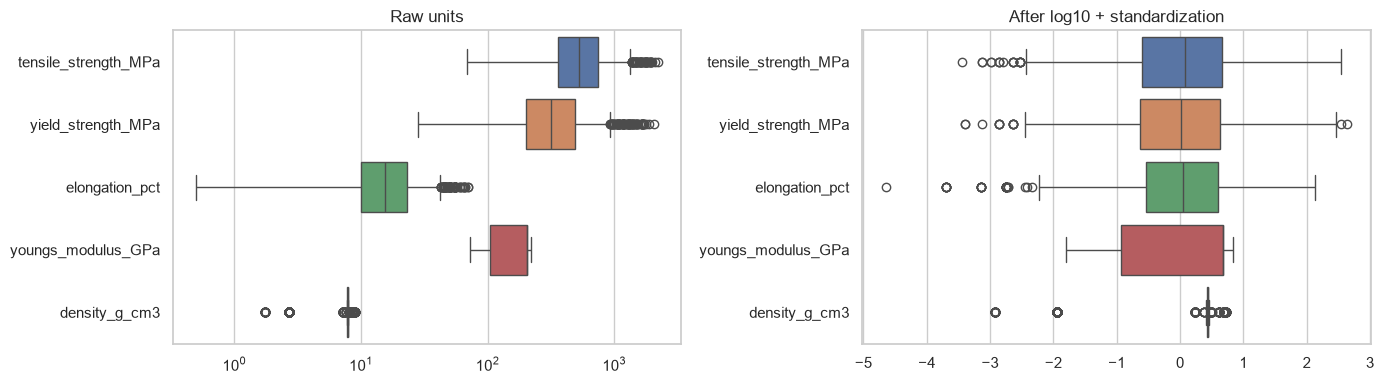

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df[CORE], ax=axes[0], orient="h"); axes[0].set_title("Raw units"); axes[0].set_xscale("log")
sns.boxplot(data=X, ax=axes[1], orient="h");        axes[1].set_title("After log10 + standardization")
plt.tight_layout(); plt.savefig("../figures/04_scaling_before_after.png", dpi=150); plt.show()

In [7]:
df.to_csv("../data/processed/materials_features.csv", index=False)
X.to_csv("../data/processed/materials_scaled.csv")
joblib.dump(scaler, "../data/processed/scaler.joblib")
print("Saved:", df.shape, X.shape)

Saved: (1235, 22) (1235, 5)
